# ЛР №2 (версия Kaggle)



План работы:
1. Знакомство с данными (EDA)
2. Подготовка данных и разбиение на train / valid
3. Метрики и выбор порога
4. Baseline (Dummy)
5. Модели: Decision Tree, Random Forest, Gradient Boosting, SVM, KNN
6. Итоговая таблица и сравнение моделей
7. Feature importance
8. Анализ ошибок и проверка признаков-идентификаторов
9. Посылка на Kaggle
10. Выводы

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

RANDOM_STATE = 42

## 1. Смотрим данные

In [2]:
train = pd.read_csv("archive/train.csv")
test = pd.read_csv("archive/test.csv")
sample = pd.read_csv("archive/sample_submission.csv")

print("train:", train.shape)
print("test:", test.shape)
print("sample_submission:", sample.shape)
train.head()

train: (891, 9)
test: (1000, 8)
sample_submission: (1000, 2)


,Id,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,87482818,3,male,22.0,1,0,7.2500,S,0
1,52187593,1,female,38.0,1,0,71.2833,C,1
2,24292843,3,female,26.0,0,0,7.9250,S,1
3,23247479,1,male,54.0,0,0,51.8625,S,0
4,83808344,3,male,2.0,3,1,21.0750,S,0


In [ ]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Id        891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    str    
 8   Survived  891 non-null    int64  
dtypes: float64(2), int64(5), str(2)
memory usage: 62.8 KB


In [4]:
# пропуски в train и test
pd.DataFrame({"train": train.isnull().sum(), "test": test.isnull().sum()})

,train,test
Age,177,161.0
Embarked,2,0.0
Fare,0,0.0
Id,0,0.0
Parch,0,0.0
Pclass,0,0.0
Sex,0,0.0
SibSp,0,0.0
Survived,0,NaN


In [ ]:
features_all = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

# одинаковые пассажиры по всем признакам
print("Строк с повтором признаков:", train.duplicated(subset=features_all).sum())
# повторы, у которых при одинаковых признаках разный ответ
groups = train.groupby(features_all, dropna=False)["Survived"].nunique()
print("Групп одинаковых пассажиров с разным Survived:", (groups > 1).sum())

Строк с повтором признаков: 127
Групп одинаковых пассажиров с разным Survived: 16


**Дубликаты и пропуски**
- В train 891 пассажир, в test — 1000. Пропуски: `Age` (~20% и в train, и в test), `Embarked` (2 в train).
- Без имени и билета 127 строк train совпадают с другими по всем признакам - это разные люди с одинаковыми
  характеристиками
- Текстовые признаки: `Sex`, `Embarked` - нужно перевести в числа.
- `Id` - технический номер строки, в модель его давать нельзя (подробнее в п. 8.1).

In [ ]:
compare = pd.DataFrame({
    "train": pd.concat([train["Sex"].value_counts(normalize=True), train["Pclass"].value_counts(normalize=True),
                        train["Embarked"].value_counts(normalize=True)]),
    "test": pd.concat([test["Sex"].value_counts(normalize=True), test["Pclass"].value_counts(normalize=True),
                       test["Embarked"].value_counts(normalize=True)])
})
print(compare.round(3))

train_rows = set(train[features_all].astype(str).apply(tuple, axis=1))
in_train = test[features_all].astype(str).apply(tuple, axis=1).isin(train_rows)
print()
print("Строк test, которые точно совпадают со строкой train:", in_train.sum())
print("Доля цен билетов test, которые встречаются в train: %.2f" % test["Fare"].isin(train["Fare"]).mean())

        train   test
male    0.648  0.656
female  0.352  0.344
3       0.551  0.562
1       0.242  0.255
2       0.207  0.183
S       0.724  0.711
C       0.189  0.191
Q       0.087  0.098

Строк test, которые точно совпадают со строкой train: 0
Доля цен билетов test, которые встречаются в train: 0.41


Доли пола, класса и портов в test почти такие же, как в train. Но ни одна строка test не совпадает со строкой train,
а больше половины цен билетов в train не встречаются. Значит, "запомнить" конкретных пассажиров train бесполезно -
нужны общие закономерности.

### Целевая переменная

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


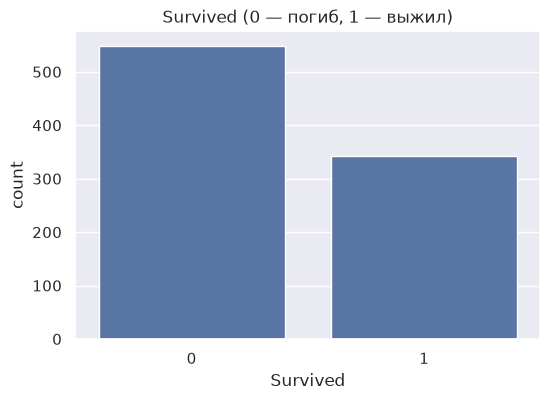

In [7]:
print(train["Survived"].value_counts())
print(train["Survived"].value_counts(normalize=True).round(3))

plt.figure(figsize=(6, 4))
sns.countplot(x="Survived", data=train)
plt.title("Survived (0 — погиб, 1 — выжил)")
plt.show()

Выжило около 38%, погибло 62%. Классы немного несбалансированы: если всем говорить "погиб", Accuracy будет 0.62,
а F1 - 0. Поэтому метрика - F1, а при разбиении нужна стратификация.

### Выживаемость по разным признакам

Для каждой группы считаем долю выживших (среднее от `Survived`).

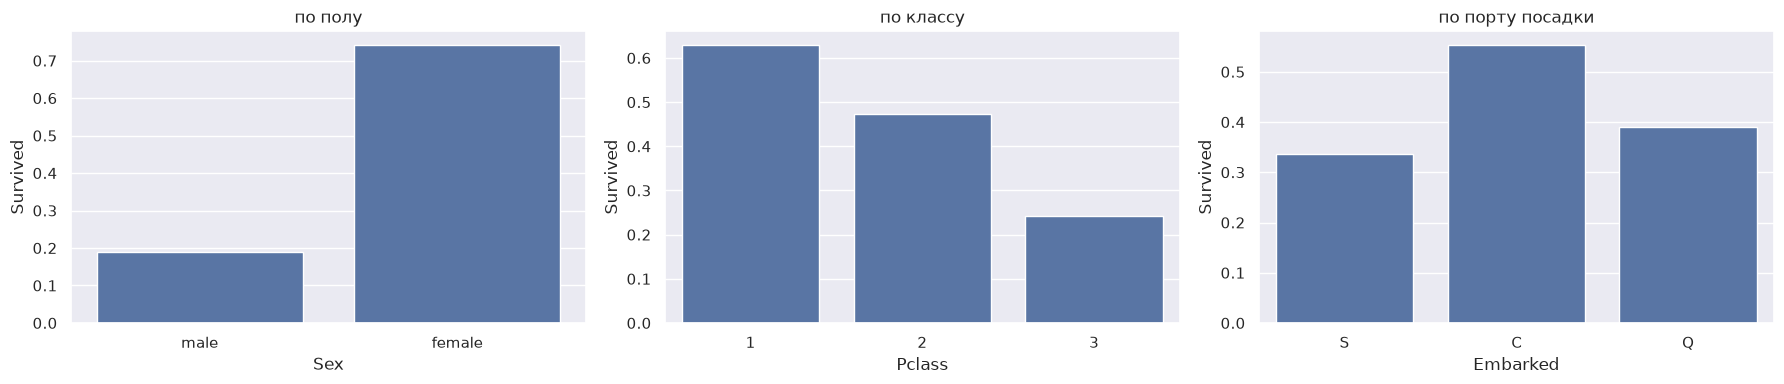

mean  count
Sex    Pclass              
female 1       0.968     94
       2       0.921     76
       3       0.500    144
male   1       0.369    122
       2       0.157    108
       3       0.135    347

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
sns.barplot(x="Sex", y="Survived", data=train, ax=axs[0], errorbar=None)
axs[0].set_title("по полу")
sns.barplot(x="Pclass", y="Survived", data=train, ax=axs[1], errorbar=None)
axs[1].set_title("по классу")
sns.barplot(x="Embarked", y="Survived", data=train, ax=axs[2], errorbar=None)
axs[2].set_title("по порту посадки")
plt.tight_layout()
plt.show()

# пол и класс вместе: доля выживших и количество людей
train.groupby(["Sex", "Pclass"])["Survived"].agg(["mean", "count"]).round(3)

In [9]:
# из какого класса пассажиры в каждом порту (доли по строкам)
pd.crosstab(train["Embarked"], train["Pclass"], normalize="index").round(2)

Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


**Выводы:**
- Выжило 74% женщин и только 19% мужчин — правило "женщины и дети первыми".
- В 1-м классе выжило 63%, во 2-м — 47%, в 3-м — 24%.
- Признаки влияют совместно: женщины 1–2 класса выжили почти все (97% и 92%), женщины 3-го — ровно половина.
  Мужчины 2–3 класса почти все погибли (16% и 14%).
- Из Шербура (C) выжило больше, но там половина пассажиров — из 1-го класса. Порт связан с выживанием через класс.

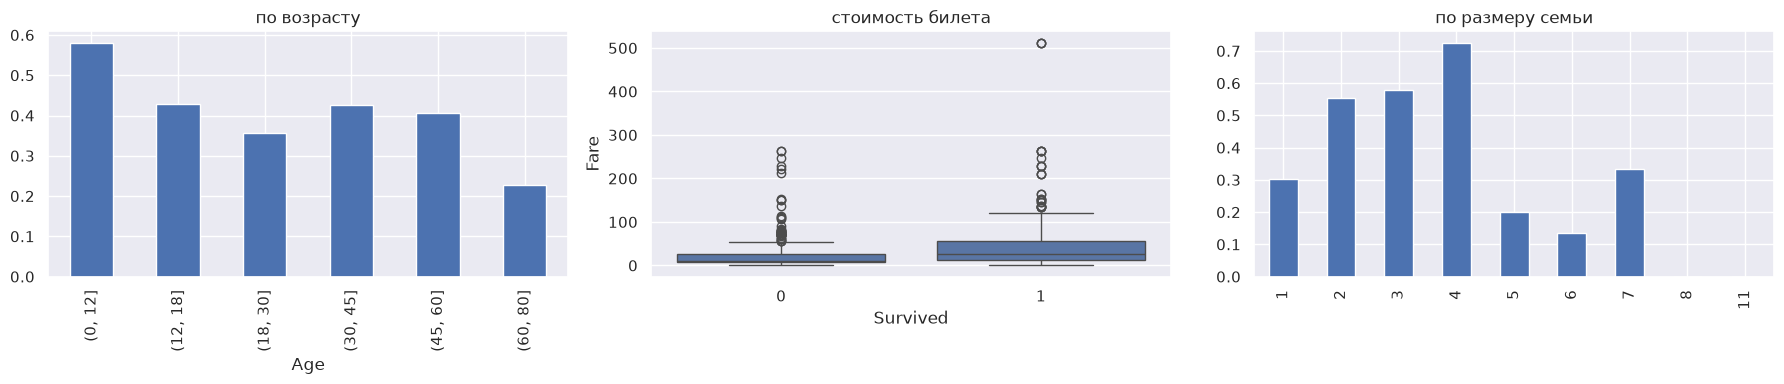

Доля выживших среди тех, у кого не указан возраст: 0.294


In [10]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))

# возраст: доля выживших по возрастным группам
age_groups = pd.cut(train["Age"], bins=[0, 12, 18, 30, 45, 60, 80])
train.groupby(age_groups)["Survived"].mean().plot(kind="bar", ax=axs[0])
axs[0].set_title("по возрасту")

# стоимость билета у погибших и выживших
sns.boxplot(x="Survived", y="Fare", data=train, ax=axs[1])
axs[1].set_title("стоимость билета")

# размер семьи = SibSp + Parch + сам пассажир
family_size = train["SibSp"] + train["Parch"] + 1
train.groupby(family_size)["Survived"].mean().plot(kind="bar", ax=axs[2])
axs[2].set_title("по размеру семьи")
plt.tight_layout()
plt.show()

print("Доля выживших среди тех, у кого не указан возраст: %.3f" % train[train["Age"].isnull()]["Survived"].mean())

- дети до 12 лет выжили в 58% случаев — чаще всех. Пожилые (60+) - реже всех. Связь нелинейная.
  Без `Name` у нас больше нет обращения `Master`, поэтому мальчиков модель сможет узнать только по возрасту,
  а у 20% пассажиров он не указан.
- у выживших билет дороже, но это в основном повтор класса. Есть выбросы до 512.
- одиночки выживали реже (30%), семьи из 2–4 человек — чаще (55–72%), большие семьи (5+) почти все
  погибли. Связь в виде горки.

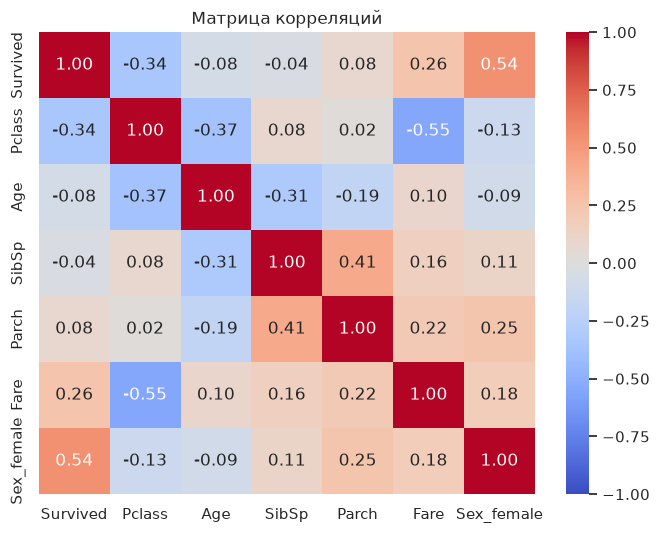

In [ ]:
numeric = train[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
numeric["Sex_female"] = (train["Sex"] == "female").astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций")
plt.show()

**Корреляции:** сильнее всего с `Survived` связаны пол (+0.54) и класс (−0.34). `Fare` (+0.26) сильно связан с классом
(−0.55). У `Age`, `SibSp`, `Parch` корреляция почти нулевая, но связь у них нелинейная (дети, размер семьи),
поэтому выбрасывать их нельзя.

## 2. Подготовка данных и выборок

### 2.1 Признаки

| Признак | Решение | Почему |
|---|---|---|
| Pclass | число | класс упорядочен (1 < 2 < 3) |
| Sex | 0/1 | бинарный признак |
| Age | пропуски → медиана | ~20% пропусков; медиана устойчива к выбросам |
| Fare | оставляем | связан с классом, но может нести доп. информацию |
| FamilySize | новый признак = SibSp + Parch + 1 | вместо SibSp и Parch, "горка" из EDA |
| Embarked | пропуски → самое частое значение, потом One-Hot | у портов нет порядка |
| Id | не используем | технический номер строки |

`FamilySize` и замена пола на 0/1 считаются по одной строке и не используют других пассажиров, поэтому их можно
делать сразу и для train, и для test — утечки нет. Медиана, самый частый порт и масштабирование учатся на данных —
их делаем только внутри Pipeline.

In [12]:
# одинаковые преобразования для train и test (каждое считается по одной строке)
for df in [train, test]:
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

num_features = ["Pclass", "Sex", "Age", "Fare", "FamilySize"]
cat_features = ["Embarked"]

X = train[num_features + cat_features]
y = train["Survived"]
X.head()

,Pclass,Sex,Age,Fare,FamilySize,Embarked
0,3,0,22.0,7.2500,2,S
1,1,1,38.0,71.2833,2,C
2,3,1,26.0,7.9250,1,S
3,1,0,54.0,51.8625,1,S
4,3,0,2.0,21.0750,5,S


### 2.2 Разбиение на train и valid

Делю `train.csv` на 80% / 20%:
- train (712) - для обучения, подбора параметров и порога (по кросс-валидации внутри него);
- valid (179) - только для финальной проверки и сравнения моделей. 

`stratify=y` — одинаковая доля выживших, `random_state=42` — одинаковое разбиение для всех моделей.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "доля выживших: %.3f" % y_train.mean())
print("Valid:", X_valid.shape, "доля выживших: %.3f" % y_valid.mean())

Train: (712, 6) доля выживших: 0.383
Valid: (179, 6) доля выживших: 0.385


### 2.3 Предобработка через Pipeline

Всё, что учится на данных (медиана `Age`, самый частый порт, категории One-Hot, среднее и std для масштабирования),
обучается только на train: `ColumnTransformer` и `Pipeline` запоминают параметры при `fit` и применяют их при `predict`.

**Масштабирование** нужно SVM и KNN: они работают с расстояниями, и без него `Fare` (до 512) перевешивает пол (0/1).
Деревьям оно не нужно - они сравнивают признак с порогом.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_pipeline(model, scale, num_cols=num_features, cat_cols=cat_features):
    # числовые: пропуски -> медиана (+ масштабирование, если scale=True)
    if scale:
        num_steps = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    else:
        num_steps = Pipeline([("imputer", SimpleImputer(strategy="median"))])

    # категориальные: пропуски -> самое частое значение, потом One-Hot
    # handle_unknown="ignore" — новая категория в test даст все нули, а не ошибку
    cat_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([("num", num_steps, num_cols), ("cat", cat_steps, cat_cols)])
    return Pipeline([("prep", preprocessor), ("model", model)])

# названия столбцов после предобработки (без приставок num__ и cat__)
def get_feature_names(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    return [name.replace("num__", "").replace("cat__", "") for name in names]

## 3. Метрики и выбор порога

|  | Предсказано погиб | Предсказано выжил |
|---|---|---|
| **На самом деле погиб** | TN | FP |
| **На самом деле выжил** | FN | TP |

- **Accuracy** = (TP + TN) / все — доля правильных ответов.
- **Precision** = TP / (TP + FP) — из названных выжившими, какая доля действительно выжила.
- **Recall** = TP / (TP + FN) — из всех выживших, какую долю модель нашла.
- **F1** = 2 · Precision · Recall / (Precision + Recall) — высокий, только если обе метрики высокие.

FP — модель переоценила шансы пассажира, FN — недооценила.

**Порог.** Модели выдают вероятность выжить, а `predict` по умолчанию говорит "выжил", если вероятность ≥ 0.5.
Порог 0.5 не обязательно лучший для F1: если снизить его, модель найдёт больше выживших (Recall растёт),
но будет чаще ошибаться (Precision падает). 

Как выбираю порог без подглядывания в valid:
1. на train делаю кросс-валидацию (5 фолдов) и получаю для каждого пассажира train вероятность от модели,
   которая его не видела
2. перебираю пороги от 0.2 до 0.7 и беру тот, при котором F1 по этим вероятностям максимальный.

Так же выбираю и параметры моделей: для каждого варианта параметров смотрю F1 при лучшем пороге.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
thresholds = np.arange(0.2, 0.71, 0.05)

def get_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return acc, prec, rec, f1

def cv_proba(model, scale):
    # out-of-fold вероятности "выжил" для каждого пассажира train
    pipe = make_pipeline(model, scale)
    return cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

def best_threshold(y_true, proba):
    # перебираем пороги и возвращаем лучший F1 и порог
    best_f1 = 0
    best_t = 0.5
    for t in thresholds:
        f1 = f1_score(y_true, (proba >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_t = t
    return best_f1, best_t

def plot_cm(y_true, y_pred, title):
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=["погиб (0)", "выжил (1)"], cmap="Blues", colorbar=False
    )
    plt.title(title)
    plt.grid(False)
    plt.show()
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    print("TN = %d, FP = %d, FN = %d, TP = %d" % (tn, fp, fn, tp))

results = []
valid_predictions = {}

def evaluate(name, pipe, cv_score, threshold):
    # метки по выбранному порогу
    pred_train = (pipe.predict_proba(X_train)[:, 1] >= threshold).astype(int)
    proba_valid = pipe.predict_proba(X_valid)[:, 1]
    pred_valid = (proba_valid >= threshold).astype(int)

    acc, prec, rec, f1 = get_metrics(y_valid, pred_valid)
    f1_train = f1_score(y_train, pred_train, zero_division=0)
    f1_05 = f1_score(y_valid, (proba_valid >= 0.5).astype(int), zero_division=0)

    print("%s (порог %.2f):" % (name, threshold))
    print("  Train F1 = %.3f" % f1_train)
    print("  Valid: Accuracy = %.3f, Precision = %.3f, Recall = %.3f, F1 = %.3f  (F1 при пороге 0.5: %.3f)"
          % (acc, prec, rec, f1, f1_05))

    results.append([name, threshold, acc, prec, rec, f1, f1_05, f1_train, cv_score])
    valid_predictions[name] = pred_valid
    return pred_valid

## 4. Baseline

`DummyClassifier(strategy="most_frequent")` всегда предсказывает самый частый класс — "погиб".

Baseline (Dummy) (порог 0.50):
  Train F1 = 0.000
  Valid: Accuracy = 0.615, Precision = 0.000, Recall = 0.000, F1 = 0.000  (F1 при пороге 0.5: 0.000)


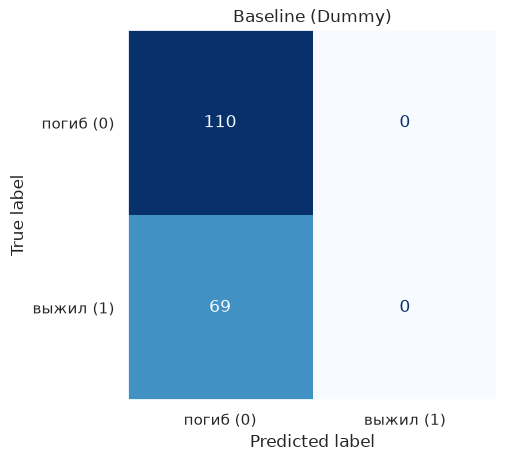

TN = 110, FP = 0, FN = 69, TP = 0


In [16]:
from sklearn.dummy import DummyClassifier

dummy = make_pipeline(DummyClassifier(strategy="most_frequent"), scale=False)
dummy.fit(X_train, y_train)
# вероятность "выжил" у dummy всегда 0, поэтому порог ни на что не влияет
pred_dummy = evaluate("Baseline (Dummy)", dummy, 0.0, 0.5)
plot_cm(y_valid, pred_dummy, "Baseline (Dummy)")

Accuracy 0.615 — просто доля погибших, но Precision, Recall и F1 равны 0: модель не нашла ни одного выжившего.

## 5. Модели

Для каждой модели перебираю параметры: для каждого варианта считаю out-of-fold вероятности на train,
подбираю порог и запоминаю лучший F1. Valid используется только для итоговой оценки.

### 5.1 Decision Tree

Дерево задаёт вопросы "признак ≤ порог?" и в каждом узле выбирает вопрос, который сильнее всего уменьшает
неоднородность Gini = 1 − (доля выживших)² − (доля погибших)². В листе - самый частый класс.

In [17]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# сначала дерево без ограничений
dt_default = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False)
dt_default.fit(X_train, y_train)
proba = cv_proba(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False)

print("Train F1 = %.3f" % f1_score(y_train, dt_default.predict(X_train)))
print("CV F1 (порог 0.5) = %.3f" % f1_score(y_train, (proba >= 0.5).astype(int)))
print("Глубина:", dt_default.named_steps["model"].get_depth(), "листьев:", dt_default.named_steps["model"].get_n_leaves())

Train F1 = 0.976
CV F1 (порог 0.5) = 0.680
Глубина: 19 листьев: 176


Явное переобучение: на train F1 = 0.98, а на кросс-валидации 0.68. Дерево глубиной 19 и со 176 листьями
запоминает конкретных пассажиров. Ограничиваю глубину и подбираю её вместе с порогом:

In [18]:
best_score = 0
for depth in [2, 3, 4, 5, 6, 8]:
    proba = cv_proba(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE), scale=False)
    score, t = best_threshold(y_train, proba)
    print("max_depth = %d: CV F1 = %.3f (порог %.2f)" % (depth, score, t))
    if score > best_score:
        best_score, best_depth, best_t = score, depth, t

print("Лучшее: max_depth =", best_depth, "порог = %.2f" % best_t, "CV F1 = %.3f" % best_score)

max_depth = 2: CV F1 = 0.707 (порог 0.40)


max_depth = 3: CV F1 = 0.737 (порог 0.45)


max_depth = 4: CV F1 = 0.728 (порог 0.35)


max_depth = 5: CV F1 = 0.725 (порог 0.25)


max_depth = 6: CV F1 = 0.714 (порог 0.35)


max_depth = 8: CV F1 = 0.714 (порог 0.35)
Лучшее: max_depth = 3 порог = 0.45 CV F1 = 0.737


Decision Tree (порог 0.45):
  Train F1 = 0.741
  Valid: Accuracy = 0.849, Precision = 0.875, Recall = 0.710, F1 = 0.784  (F1 при пороге 0.5: 0.784)


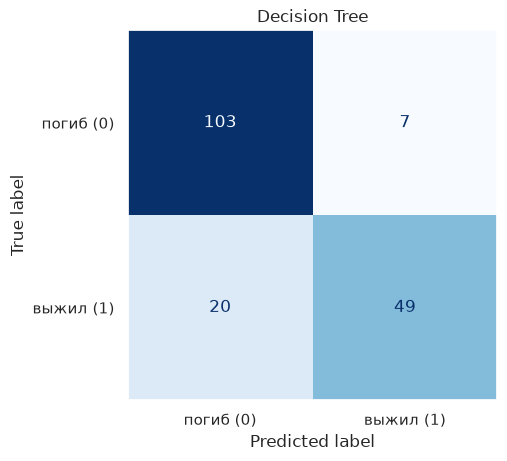

TN = 103, FP = 7, FN = 20, TP = 49


In [19]:
dt = make_pipeline(DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE), scale=False)
dt.fit(X_train, y_train)
dt_threshold = best_t

pred_dt = evaluate("Decision Tree", dt, best_score, dt_threshold)
plot_cm(y_valid, pred_dt, "Decision Tree")

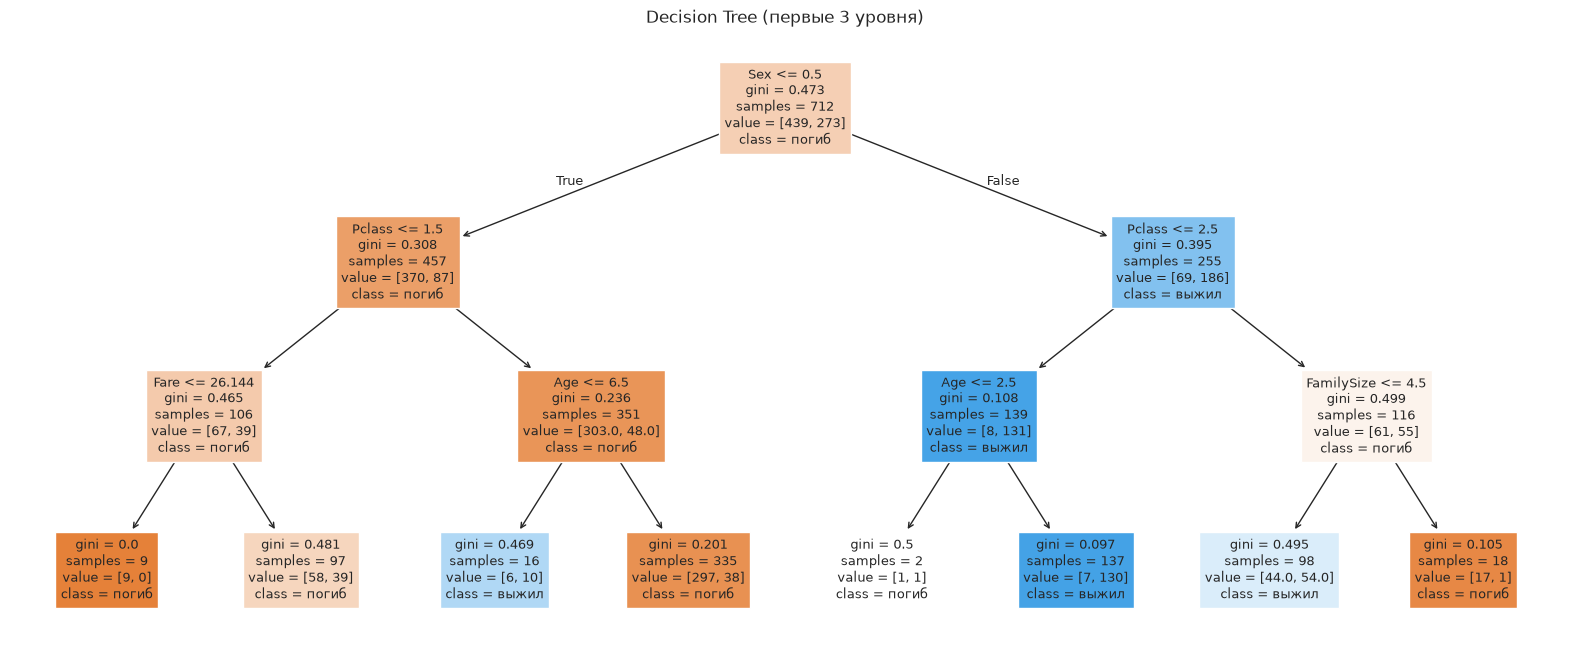

Sex           0.632
Pclass        0.242
Age           0.058
FamilySize    0.050
Fare          0.018
Embarked_C    0.000
Embarked_Q    0.000
Embarked_S    0.000
dtype: float64


In [20]:
plt.figure(figsize=(20, 8))
plot_tree(dt.named_steps["model"], feature_names=get_feature_names(dt),
          class_names=["погиб", "выжил"], filled=True, fontsize=9, max_depth=3)
plt.title("Decision Tree (первые 3 уровня)")
plt.show()

dt_importance = pd.Series(dt.named_steps["model"].feature_importances_,
                          index=get_feature_names(dt)).sort_values(ascending=False)
print(dt_importance.round(3))

- **Первый вопрос — пол.**
- **Женщины:** 1–2 класс → выжила; 3 класс → выжила, только если семья не больше 4 человек.
- **Мужчины:** 1 класс → погиб; 2–3 класс → погиб, кроме мальчиков до 6.5 лет (10 из 16 выжили).
  Обращения `Master` в данных нет, и дерево само нашло детей по возрасту.

 Важность у дерева сосредоточена
в поле (0.63) и классе (0.24).

### 5.2 Random Forest

Много деревьев, каждое учится на своей bootstrap-выборке и в каждом узле выбирает вопрос среди случайной части признаков.
Ответ — усреднение (голосование) деревьев. Разные деревья ошибаются по-разному, и усреднение гасит их ошибки.

In [21]:
from sklearn.ensemble import RandomForestClassifier

best_score = 0
for depth in [4, 5, 7, 10, None]:
    model = RandomForestClassifier(n_estimators=300, max_depth=depth, random_state=RANDOM_STATE, n_jobs=-1)
    proba = cv_proba(model, scale=False)
    score, t = best_threshold(y_train, proba)
    print("max_depth = %s: CV F1 = %.3f (порог %.2f)" % (depth, score, t))
    if score > best_score:
        best_score, best_depth, best_t = score, depth, t

print("Лучшее: max_depth =", best_depth, "порог = %.2f" % best_t, "CV F1 = %.3f" % best_score)

max_depth = 4: CV F1 = 0.740 (порог 0.35)


max_depth = 5: CV F1 = 0.745 (порог 0.35)


max_depth = 7: CV F1 = 0.752 (порог 0.30)


max_depth = 10: CV F1 = 0.748 (порог 0.45)


max_depth = None: CV F1 = 0.725 (порог 0.45)
Лучшее: max_depth = 7 порог = 0.30 CV F1 = 0.752


Random Forest (порог 0.30):
  Train F1 = 0.820
  Valid: Accuracy = 0.855, Precision = 0.803, Recall = 0.826, F1 = 0.814  (F1 при пороге 0.5: 0.787)


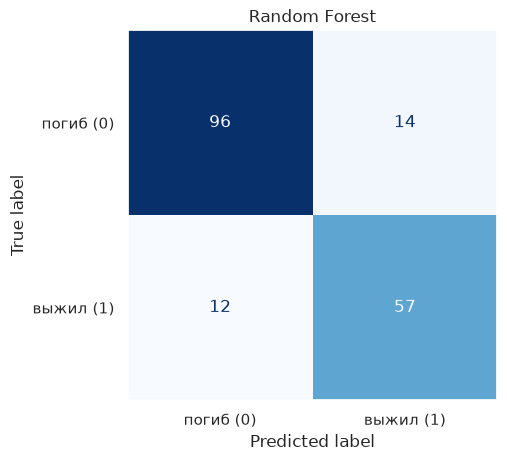

TN = 96, FP = 14, FN = 12, TP = 57
Sex           0.355
Fare          0.220
Age           0.162
Pclass        0.127
FamilySize    0.089
Embarked_C    0.020
Embarked_S    0.017
Embarked_Q    0.009
dtype: float64


In [22]:
rf = make_pipeline(RandomForestClassifier(n_estimators=300, max_depth=best_depth,
                                          random_state=RANDOM_STATE, n_jobs=-1), scale=False)
rf.fit(X_train, y_train)
rf_depth, rf_threshold = best_depth, best_t

pred_rf = evaluate("Random Forest", rf, best_score, rf_threshold)
plot_cm(y_valid, pred_rf, "Random Forest")

rf_importance = pd.Series(rf.named_steps["model"].feature_importances_,
                          index=get_feature_names(rf)).sort_values(ascending=False)
print(rf_importance.round(3))

### 5.3 Gradient Boosting

Неглубокие деревья строятся по очереди: каждое следующее исправляет ошибки предыдущих (учится на антиградиенте log loss).
Ответ - сумма деревьев с весом `learning_rate`, которая переводится в вероятность.

In [23]:
from sklearn.ensemble import GradientBoostingClassifier

params_list = [
    # n_estimators — число деревьев, learning_rate — размер шага, max_depth — глубина деревьев
    {"n_estimators": 100, "learning_rate": 0.1,  "max_depth": 3},   # по умолчанию
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 3},
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 2},
    {"n_estimators": 200, "learning_rate": 0.1,  "max_depth": 2},
    {"n_estimators": 100, "learning_rate": 0.1,  "max_depth": 4},
]

best_score = 0
for params in params_list:
    model = GradientBoostingClassifier(n_estimators=params["n_estimators"], learning_rate=params["learning_rate"],
                                       max_depth=params["max_depth"], random_state=RANDOM_STATE)
    proba = cv_proba(model, scale=False)
    score, t = best_threshold(y_train, proba)
    print(params, "CV F1 = %.3f (порог %.2f)" % (score, t))
    if score > best_score:
        best_score, best_params, best_t = score, params, t

print("Лучшее:", best_params, "порог = %.2f" % best_t, "CV F1 = %.3f" % best_score)

{'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3} CV F1 = 0.746 (порог 0.40)


{'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 3} CV F1 = 0.745 (порог 0.40)


{'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2} CV F1 = 0.742 (порог 0.30)


{'n_estimators': 200, 'learning_rate': 0.1, 'max_depth': 2} CV F1 = 0.740 (порог 0.45)


{'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 4} CV F1 = 0.750 (порог 0.45)
Лучшее: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 4} порог = 0.45 CV F1 = 0.750


Gradient Boosting (порог 0.45):
  Train F1 = 0.919
  Valid: Accuracy = 0.877, Precision = 0.927, Recall = 0.739, F1 = 0.823  (F1 при пороге 0.5: 0.800)


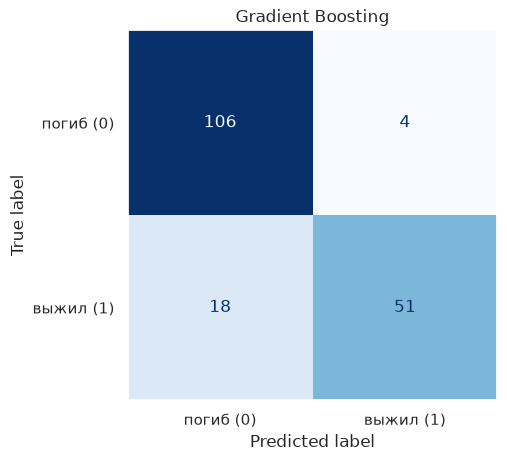

TN = 106, FP = 4, FN = 18, TP = 51
Sex           0.387
Fare          0.199
Age           0.176
Pclass        0.150
FamilySize    0.074
Embarked_C    0.007
Embarked_S    0.005
Embarked_Q    0.002
dtype: float64


In [24]:
gb = make_pipeline(GradientBoostingClassifier(n_estimators=best_params["n_estimators"],
                                              learning_rate=best_params["learning_rate"],
                                              max_depth=best_params["max_depth"],
                                              random_state=RANDOM_STATE), scale=False)
gb.fit(X_train, y_train)
gb_threshold = best_t

pred_gb = evaluate("Gradient Boosting", gb, best_score, gb_threshold)
plot_cm(y_valid, pred_gb, "Gradient Boosting")

gb_importance = pd.Series(gb.named_steps["model"].feature_importances_,
                          index=get_feature_names(gb)).sort_values(ascending=False)
print(gb_importance.round(3))

### 5.4 Support Vector Machine

SVM ищет границу между классами с максимальным зазором. С ядром RBF граница может быть нелинейной.
`C` — штраф за ошибки на train: большой `C` — граница подстраивается под каждую точку, маленький — граница мягче.

Чтобы выбирать порог, нужна вероятность: `probability=True` (SVM сам переводит расстояние до границы в вероятность).

**Масштабирование обязательно**: зазор и ядро считаются через расстояния. Проверка по кросс-валидации:

In [25]:
from sklearn.svm import SVC

for scale in [False, True]:
    proba = cv_proba(SVC(probability=True, random_state=RANDOM_STATE), scale=scale)
    print("SVM, масштабирование = %s: CV F1 (порог 0.5) = %.3f" % (scale, f1_score(y_train, (proba >= 0.5).astype(int))))

SVM, масштабирование = False: CV F1 (порог 0.5) = 0.442


SVM, масштабирование = True: CV F1 (порог 0.5) = 0.729


In [26]:
best_score = 0
for C in [0.1, 0.5, 1, 3, 10]:
    proba = cv_proba(SVC(C=C, probability=True, random_state=RANDOM_STATE), scale=True)
    score, t = best_threshold(y_train, proba)
    print("C = %s: CV F1 = %.3f (порог %.2f)" % (C, score, t))
    if score > best_score:
        best_score, best_C, best_t = score, C, t

print("Лучшее: C =", best_C, "порог = %.2f" % best_t, "CV F1 = %.3f" % best_score)

C = 0.1: CV F1 = 0.727 (порог 0.30)


C = 0.5: CV F1 = 0.746 (порог 0.40)


C = 1: CV F1 = 0.737 (порог 0.45)


C = 3: CV F1 = 0.721 (порог 0.50)


C = 10: CV F1 = 0.717 (порог 0.60)
Лучшее: C = 0.5 порог = 0.40 CV F1 = 0.746


SVM (порог 0.40):
  Train F1 = 0.752
  Valid: Accuracy = 0.866, Precision = 0.895, Recall = 0.739, F1 = 0.810  (F1 при пороге 0.5: 0.803)


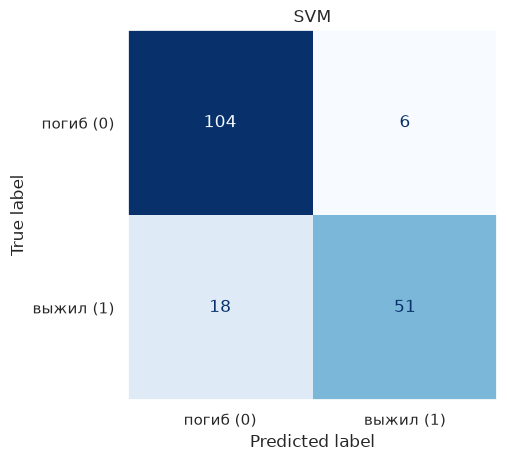

TN = 104, FP = 6, FN = 18, TP = 51


In [27]:
svm = make_pipeline(SVC(C=best_C, probability=True, random_state=RANDOM_STATE), scale=True)
svm.fit(X_train, y_train)
svm_threshold = best_t

pred_svm = evaluate("SVM", svm, best_score, svm_threshold)
plot_cm(y_valid, pred_svm, "SVM")

### 5.5 K-Nearest Neighbors

KNN запоминает train, а для нового пассажира находит `k` ближайших по расстоянию и смотрит, какая доля из них выжила. Масштаб важен: без него соседями будут люди с похожей ценой билета,
а пол почти не будет учитываться.

In [28]:
from sklearn.neighbors import KNeighborsClassifier

for scale in [False, True]:
    proba = cv_proba(KNeighborsClassifier(n_neighbors=5), scale=scale)
    print("KNN (k=5), масштабирование = %s: CV F1 (порог 0.5) = %.3f" % (scale, f1_score(y_train, (proba >= 0.5).astype(int))))

KNN (k=5), масштабирование = False: CV F1 (порог 0.5) = 0.573


KNN (k=5), масштабирование = True: CV F1 (порог 0.5) = 0.716


In [29]:
best_score = 0
for k in [3, 5, 9, 15, 21]:
    proba = cv_proba(KNeighborsClassifier(n_neighbors=k), scale=True)
    score, t = best_threshold(y_train, proba)
    print("k = %d: CV F1 = %.3f (порог %.2f)" % (k, score, t))
    if score > best_score:
        best_score, best_k, best_t = score, k, t

print("Лучшее: k =", best_k, "порог = %.2f" % best_t, "CV F1 = %.3f" % best_score)

k = 3: CV F1 = 0.707 (порог 0.20)


k = 5: CV F1 = 0.740 (порог 0.25)


k = 9: CV F1 = 0.731 (порог 0.25)


k = 15: CV F1 = 0.729 (порог 0.25)


k = 21: CV F1 = 0.738 (порог 0.30)
Лучшее: k = 5 порог = 0.25 CV F1 = 0.740


KNN (порог 0.25):
  Train F1 = 0.813
  Valid: Accuracy = 0.816, Precision = 0.737, Recall = 0.812, F1 = 0.772  (F1 при пороге 0.5: 0.744)


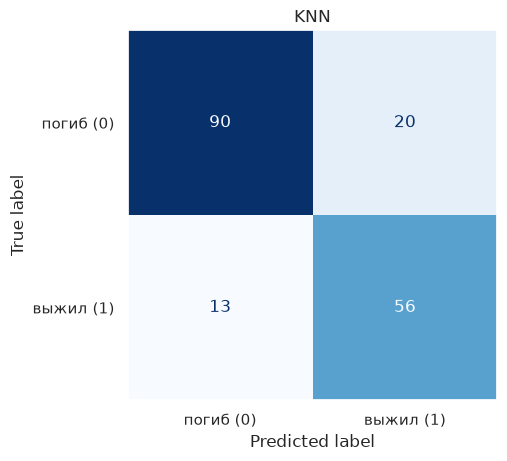

TN = 90, FP = 20, FN = 13, TP = 56


In [30]:
knn = make_pipeline(KNeighborsClassifier(n_neighbors=best_k), scale=True)
knn.fit(X_train, y_train)
knn_threshold = best_t

pred_knn = evaluate("KNN", knn, best_score, knn_threshold)
plot_cm(y_valid, pred_knn, "KNN")

## 6. Сравнение моделей

Все модели: одинаковый train, одинаковая кросс-валидация для выбора параметров и порога, одинаковый valid.

In [31]:
results_table = pd.DataFrame(results, columns=["Модель", "Порог", "Accuracy", "Precision", "Recall", "F1",
                                                "F1 (порог 0.5)", "F1 (train)", "F1 (CV)"])
results_table["F1 > 0.70"] = results_table["F1"] > 0.70
results_table.round(3)

,Модель,Порог,Accuracy,Precision,Recall,F1,F1 (порог 0.5),F1 (train),F1 (CV),F1 > 0.70
0,Baseline (Dummy),0.50,0.615,0.000,0.000,0.000,0.000,0.000,0.000,False
1,Decision Tree,0.45,0.849,0.875,0.710,0.784,0.784,0.741,0.737,True
2,Random Forest,0.30,0.855,0.803,0.826,0.814,0.787,0.820,0.752,True
3,Gradient Boosting,0.45,0.877,0.927,0.739,0.823,0.800,0.919,0.750,True
4,SVM,0.40,0.866,0.895,0.739,0.810,0.803,0.752,0.746,True
5,KNN,0.25,0.816,0.737,0.812,0.772,0.744,0.813,0.740,True


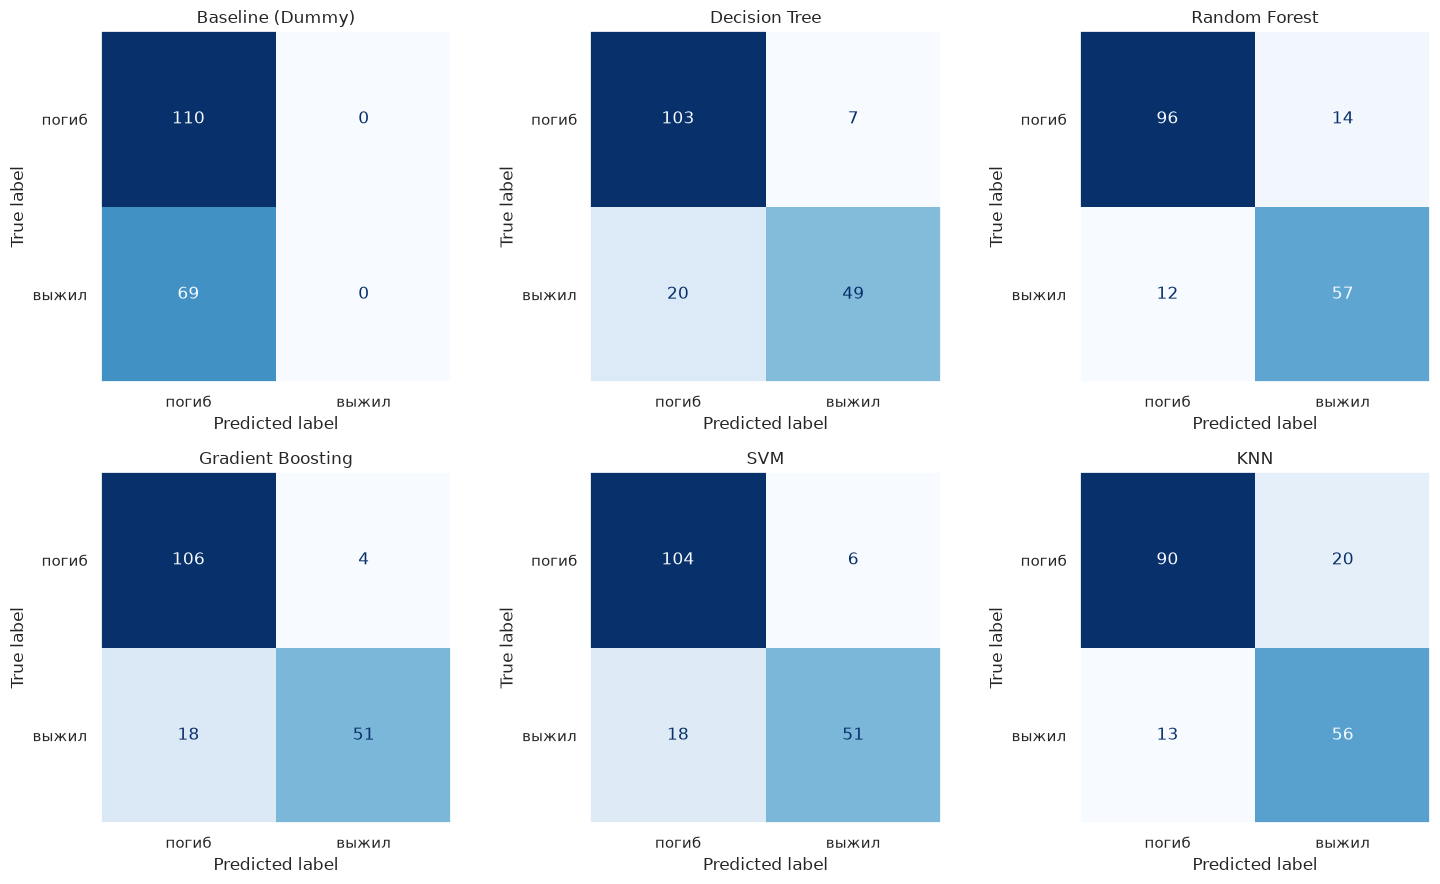

In [32]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
axs = axs.flatten()
for i, name in enumerate(valid_predictions):
    ConfusionMatrixDisplay.from_predictions(y_valid, valid_predictions[name], display_labels=["погиб", "выжил"],
                                            cmap="Blues", colorbar=False, ax=axs[i])
    axs[i].set_title(name)
    axs[i].grid(False)
plt.tight_layout()
plt.show()

In [33]:
# лучшая модель — по F1 на кросс-валидации (не по valid)
best_row = results_table.loc[results_table["F1 (CV)"].idxmax()]
best_name = best_row["Модель"]
print("Лучшая модель по CV:", best_name, "| порог %.2f | F1 (CV) = %.3f | F1 (valid) = %.3f"
      % (best_row["Порог"], best_row["F1 (CV)"], best_row["F1"]))

Лучшая модель по CV: Random Forest | порог 0.30 | F1 (CV) = 0.752 | F1 (valid) = 0.814


**Анализ результатов:**
1. Все 5 моделей превзошли baseline и прошли порог F1 > 0.70: на valid F1 от 0.77 до 0.82.
2. Подбор порога помогает. у всех моделей лучший порог ≤ 0.5 (от 0.25 у KNN до 0.45 у дерева и бустинга).
   Модели "осторожничают", и если говорить "выжил" уже при вероятности 25–45%, они находят больше выживших.
   На valid это дало +0.02–0.03 F1 лесу, бустингу и KNN (сравните `F1` и `F1 (порог 0.5)`). У дерева порог 0.45
   ничего не поменял: у неглубокого дерева мало разных вероятностей.
3. Разница между моделями небольшая: по CV все в диапазоне 0.737–0.752. На valid всего 69 выживших, одна ошибка
   меняет F1 примерно на 0.01, поэтому лучшую модель выбираю по CV - это Random Forest (0.752), бустинг почти
   такой же (0.750). На valid лучше всех бустинг (0.823), но выбирать по valid значило бы подгонять под неё.
4. **Переобучение:** у бустинга F1 на train 0.92 против 0.75 на CV — он сильнее всех подстраивается под train.
   У дерева и SVM train и CV близки.
5. SVM и KNN без масштабирования работают намного хуже (CV F1 0.44 и 0.57 против 0.73 и 0.72).

## 7. Feature importance

### 7.1 Встроенная важность у деревьев

Суммарное уменьшение Gini в разбиениях по признаку, нормированное на 1 (у ансамблей — среднее по деревьям).

            Decision Tree  Random Forest  Gradient Boosting
Sex                 0.632          0.355              0.387
Fare                0.018          0.220              0.199
Age                 0.058          0.162              0.176
Pclass              0.242          0.127              0.150
FamilySize          0.050          0.089              0.074
Embarked_C          0.000          0.020              0.007
Embarked_S          0.000          0.017              0.005
Embarked_Q          0.000          0.009              0.002


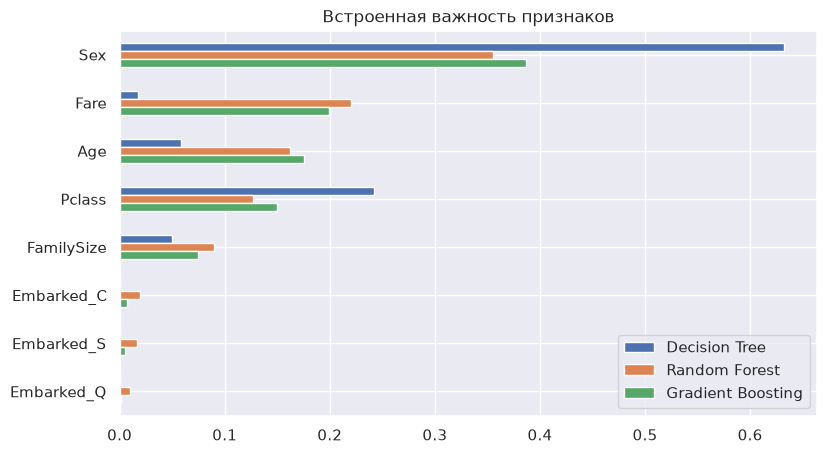

In [34]:
compare = pd.DataFrame({"Decision Tree": dt_importance, "Random Forest": rf_importance, "Gradient Boosting": gb_importance})
compare = compare.sort_values("Random Forest", ascending=False)
print(compare.round(3))

compare.plot(kind="barh", figsize=(9, 5))
plt.gca().invert_yaxis()
plt.title("Встроенная важность признаков")
plt.show()

### 7.2 Permutation importance

Перемешиваем один признак на valid и смотрим, насколько упал F1 (с выбранным для модели порогом).
Работает для любой модели, в том числе SVM и KNN. Valid здесь не используется для выбора — только для объяснения.

            Decision Tree  Random Forest  Gradient Boosting    SVM    KNN
Sex                 0.373          0.214              0.287  0.385  0.202
Age                 0.044          0.082              0.109  0.067  0.064
Pclass              0.014          0.038              0.072  0.029  0.073
FamilySize          0.027          0.036              0.072  0.040  0.013
Fare                0.000          0.035              0.069 -0.000  0.027
Embarked            0.000          0.019              0.018  0.003  0.020


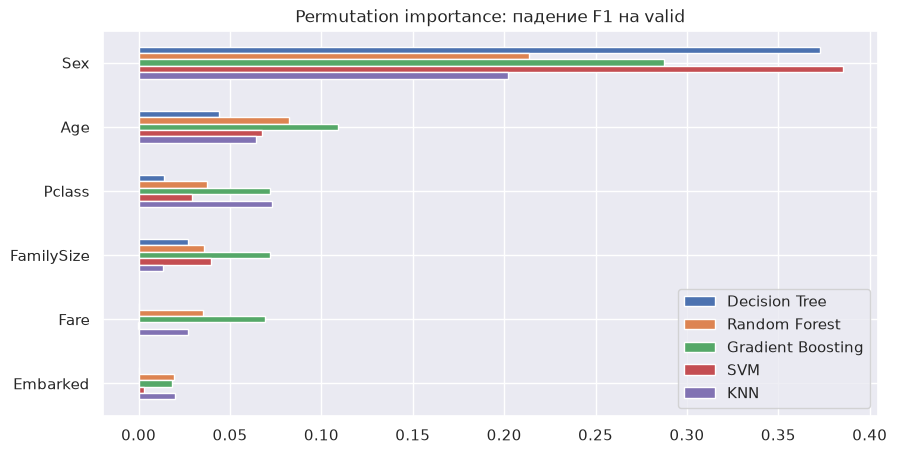

In [35]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer

models = {"Decision Tree": (dt, dt_threshold), "Random Forest": (rf, rf_threshold),
          "Gradient Boosting": (gb, gb_threshold), "SVM": (svm, svm_threshold), "KNN": (knn, knn_threshold)}

perm_table = {}
for name in models:
    pipe, t = models[name]
    # F1 с порогом модели: на вход scorer получает модель, X и y
    def f1_with_threshold(estimator, X_part, y_part, t=t):
        return f1_score(y_part, (estimator.predict_proba(X_part)[:, 1] >= t).astype(int), zero_division=0)
    perm = permutation_importance(pipe, X_valid, y_valid, scoring=f1_with_threshold,
                                  n_repeats=20, random_state=RANDOM_STATE)
    perm_table[name] = pd.Series(perm.importances_mean, index=X_valid.columns)

perm_table = pd.DataFrame(perm_table).sort_values("Random Forest", ascending=False)
print(perm_table.round(3))

perm_table.plot(kind="barh", figsize=(10, 5))
plt.gca().invert_yaxis()
plt.title("Permutation importance: падение F1 на valid")
plt.show()

**Выводы по важности признаков:**
1. Самый важный признак - пол: у всех моделей и обоими способами он на 1-м месте (перемешивание пола роняет F1
   на 0.20–0.39).
2. Дальше - возраст** и класс (падение F1 до 0.11 и 0.07), потом размер семьи.
3. `Fare` у леса во встроенной важности на 2-м месте (0.22), а в permutation importance - 0.035, на уровне
   размера семьи. Встроенная важность завышает признаки с большим количеством разных значений.


Нельзя сказать, что важный признак - причина выживания. Importance показывает, на что опирается модель,
а не что вызвало выживание

## 8. Анализ ошибок лучшей модели

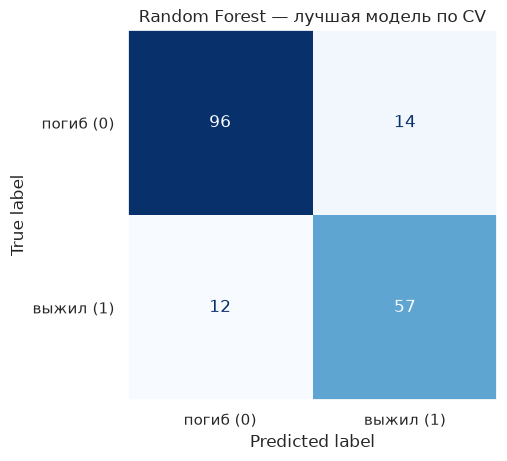

TN = 96, FP = 14, FN = 12, TP = 57


type
TN    96
TP    57
FP    14
FN    12
Name: count, dtype: int64


In [36]:
best_pipe, best_threshold_value = models[best_name]
pred_best = valid_predictions[best_name]
plot_cm(y_valid, pred_best, best_name + " — лучшая модель по CV")

errors_df = X_valid.copy()
errors_df["Survived"] = y_valid
errors_df["proba"] = best_pipe.predict_proba(X_valid)[:, 1].round(2)
errors_df["pred"] = pred_best

def answer_type(row):
    if row["Survived"] == 1 and row["pred"] == 1:
        return "TP"
    if row["Survived"] == 0 and row["pred"] == 0:
        return "TN"
    if row["Survived"] == 0 and row["pred"] == 1:
        return "FP"
    return "FN"

errors_df["type"] = errors_df.apply(answer_type, axis=1)
errors_df["Sex_text"] = errors_df["Sex"].map({0: "male", 1: "female"})
print(errors_df["type"].value_counts())

In [37]:
# ошибки по группам "пол + класс"
groups = []
for (sex, pclass), part in errors_df.groupby(["Sex_text", "Pclass"]):
    groups.append([sex, pclass, len(part), round(part["Survived"].mean(), 2), round(part["pred"].mean(), 2),
                   round(part["type"].isin(["FP", "FN"]).mean(), 2),
                   (part["type"] == "FP").sum(), (part["type"] == "FN").sum()])

pd.DataFrame(groups, columns=["пол", "класс", "человек", "выжило (факт)", "выжило (прогноз)", "доля ошибок", "FP", "FN"])

,пол,класс,человек,выжило (факт),выжило (прогноз),доля ошибок,FP,FN
0,female,1,16,1.00,1.00,0.00,0,0
1,female,2,15,0.93,1.00,0.07,1,0
2,female,3,28,0.61,0.68,0.21,4,2
3,male,1,16,0.38,0.75,0.38,6,0
4,male,2,28,0.14,0.18,0.11,2,1
5,male,3,76,0.16,0.05,0.13,1,9


In [38]:
show_cols = ["Sex_text", "Pclass", "Age", "Fare", "FamilySize", "Embarked", "Survived", "proba", "type"]
print("FP — модель сказала 'выжил', а человек погиб:")
print(errors_df[errors_df["type"] == "FP"][show_cols].to_string())
print()
print("FN — модель сказала 'погиб', а человек выжил:")
print(errors_df[errors_df["type"] == "FN"][show_cols].to_string())

FP — модель сказала 'выжил', а человек погиб:
    Sex_text  Pclass   Age      Fare  FamilySize Embarked  Survived  proba type
25      male       1  40.0   27.7208           1        C         0   0.41   FP
438   female       3  26.0   16.1000           2        S         0   0.59   FP
318     male       1  30.0   27.7500           1        C         0   0.37   FP
111     male       1  51.0   61.3792           2        C         0   0.54   FP
563   female       3  18.0    7.7750           1        S         0   0.51   FP
763     male       1  50.0  106.4250           2        C         0   0.52   FP
627     male       1  42.0   52.0000           2        S         0   0.39   FP
335   female       3  22.0    9.8375           1        S         0   0.37   FP
205     male       3  23.5    7.2292           1        C         0   0.31   FP
740     male       1  37.0   29.7000           2        C         0   0.50   FP
823   female       3  41.0   20.2125           3        S         0   0.45

**Какие ошибки и у кого:**
- Из-за низкого порога (0.30) лес ошибается в обе стороны примерно поровну: 14 FP и 12 FN.
  
- Мужчины 1-го класса - 6 FP из 16: модель спасла 75% из них, а выжили 38%. 
- Мужчины 3-го класса - 9 FN: выжившие мужчины, в основном с дешёвыми билетами (7–10) и вероятностью около 0.1.
  Для модели они ничем не отличаются от сотен погибших.
- Женщины 3-го класса - 4 FP и 2 FN: исход в этой группе 50/50, угадать его по признакам почти невозможно.
- Женщины 1–2 класса предсказываются почти идеально.

Как и раньше, модель выучила правило "женщины и дети первыми" и ошибается там, где оно не давало однозначного ответа.

### 8.1 Признак `Id`

Проверю, не связан ли он с ответом
(если бы, например, выжившим давали номера по порядку, это была бы утечка).

In [39]:
# у части строк номера идут подряд, у остальных — случайные
sequential = train["Id"] < 10001000
print("Строк с номерами подряд (10000000...):", sequential.sum())
print("Доля выживших у них: %.3f, у остальных: %.3f" % (train[sequential]["Survived"].mean(),
                                                       train[~sequential]["Survived"].mean()))
print("В test таких номеров:", (test["Id"] < 10001000).sum())
print()
print(train.groupby(pd.qcut(train["Id"], 5))["Survived"].agg(["mean", "count"]).round(3))

Строк с номерами подряд (10000000...): 267
Доля выживших у них: 0.382, у остальных: 0.385
В test таких номеров: 0

                            mean  count
Id                                     
(9999999.999, 10000178.0]  0.385    179
(10000178.0, 20879288.0]   0.376    178
(20879288.0, 49564669.0]   0.438    178
(49564669.0, 73755484.0]   0.348    178
(73755484.0, 99839297.0]   0.371    178


In [40]:
# что будет, если дать Id модели: лес без ограничения глубины (лучше всех умеет "запоминать")
def rf_model():
    return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

from sklearn.model_selection import cross_val_score

for title, num_cols in [("наши признаки", num_features), ("+ Id", num_features + ["Id"])]:
    X_tr = train.loc[X_train.index, num_cols + cat_features]
    pipe = make_pipeline(rf_model(), scale=False, num_cols=num_cols)
    scores = cross_val_score(pipe, X_tr, y_train, cv=cv, scoring="f1")
    pipe.fit(X_tr, y_train)
    print("%-15s train F1 = %.3f, CV F1 = %.3f (разброс между фолдами std = %.3f)"
          % (title, f1_score(y_train, pipe.predict(X_tr)), scores.mean(), scores.std()))
    if title == "+ Id":
        imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=get_feature_names(pipe))
        print(imp.sort_values(ascending=False).round(3).head(5))

наши признаки   train F1 = 0.976, CV F1 = 0.722 (разброс между фолдами std = 0.042)


+ Id            train F1 = 1.000, CV F1 = 0.734 (разброс между фолдами std = 0.035)
Sex       0.244
Fare      0.208
Id        0.194
Age       0.170
Pclass    0.084
dtype: float64


- Доля выживших не зависит от `Id`: у "последовательных" и случайных номеров она одинаковая, по группам `Id` тоже
  без закономерности. Утечки через `Id` нет.
- Но если дать `Id` лесу, он ставит его **на 3-е место** по встроенной важности (выше класса!), а F1 на train
  становится 1.00. CV F1 меняется на 0.01 — меньше разброса между фолдами (std около 0.04), то есть это шум.
  У номера сотни разных значений, и по нему легко найти случайно "удачные" разбиения на train.
  Высокая важность ≠ полезный признак.

## 9. Посылка на Kaggle

Модель и порог выбраны. Обучаю лучшую модель с теми же параметрами на всём `train.csv`,
предсказываю вероятности для `test.csv`.

In [43]:
from sklearn.base import clone

# clone — новая необученная модель с теми же параметрами и той же предобработкой
final_model = clone(best_pipe)
final_model.fit(X, y)

X_test = test[num_features + cat_features]
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold_value).astype(int)

submission = pd.DataFrame({"Id": test["Id"], "Survived": test_pred})
submission.to_csv("submission.csv", index=False)

print("Модель:", best_name, "| порог %.2f" % best_threshold_value)
print("Доля 'выжил' в предсказаниях: %.3f (в train выжило %.3f)" % (test_pred.mean(), y.mean()))
submission.head()

Модель: Random Forest | порог 0.30
Доля 'выжил' в предсказаниях: 0.507 (в train выжило 0.384)


,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,1
3,16342593,0
4,10829305,0


In [44]:
# проверка формата посылки
check = pd.read_csv("submission.csv")
print("Колонки:", list(check.columns))
print("Строк:", len(check))
print("Id совпадают с шаблоном (тот же порядок):", (check["Id"].values == sample["Id"].values).all())
print("Повторов Id:", check["Id"].duplicated().sum(), "| пропусков:", check.isnull().sum().sum())
print("Значения Survived:", sorted(check["Survived"].unique()))

Колонки: ['Id', 'Survived']
Строк: 1000
Id совпадают с шаблоном (тот же порядок): True
Повторов Id: 0 | пропусков: 0
Значения Survived: [np.int64(0), np.int64(1)]




Модель говорит "выжил" для ~51% пассажиров test, хотя в train выжило 38%. Это следствие низкого порога 0.30:
пассажиры с "пограничной" вероятностью 0.3–0.5 (в основном мужчины 1-го класса и женщины 3-го) попадают в "выжил".
F1 поощряет находить выживших, поэтому порог по CV и получился низким. На valid с этим порогом было 14 FP и 12 FN.



## 10. Выводы

1. **Данные.** 891 пассажир в train (те же, что в исходном датасете, но без `Name`, `Ticket`, `Cabin`, `PassengerId`)
   и 1000 новых пассажиров в test — похожих на train, но ни один не совпадает. Выжило 38%, поэтому метрика — F1.
   Главные факторы по EDA — пол, класс, возраст (дети) и размер семьи.
2. **Подготовка.** Признаки `Pclass, Sex, Age, Fare, FamilySize, Embarked`; `Id` не используется.
   Пропуски — медианой и самым частым значением внутри Pipeline (только по train). Разбиение 80/20 со стратификацией.
3. **Выбор модели, параметров и порога** — по out-of-fold вероятностям на кросс-валидации внутри train, valid только
   для проверки. Подбор порога дал +0.02–0.03 F1 большинству моделей; лучшие пороги 0.25–0.45, а не 0.5.
4. **Модели.** Все пять прошли порог: на valid F1 от 0.77 (KNN) до 0.82 (бустинг). Лучшая по CV — Random Forest
   (глубина 7, порог 0.30): CV F1 0.752, valid 0.814. Разница между моделями на уровне шума.
5. **Важность признаков.** Главный — пол, дальше возраст и класс. Встроенная важность завышает `Fare` и даже бессмысленный `Id`.
6. **Ошибки.** Модель путается в тех же группах, что и раньше: мужчины 1-го класса (порог 0.30 "спасает" лишних),
   мужчины 3-го класса (везучие выжившие), женщины 3-го класса (50/50).
7. **Идентификаторы.** `Id`, `PassengerId`, `Name`, `Ticket` позволяют только запомнить пассажиров train и не улучшают
   качество; `Cabin` подозрителен на утечку. Правильно, что их нет в данных Kaggle.
8. **Посылка:** лес обучен на всём `train.csv`, предсказания для 1000 пассажиров test сохранены в `submission.csv`.